# 04 · Clean performance and concept drift

**RQ1 – Clean performance.** On unperturbed test data, how does MFGraph compare with classical baselines trained on the
same information without the graph structure?

**RQ2 – Concept drift.** Models are trained on the *past* and tested on the *future*:
* **PE**: trained on January 2018, tested separately on each month February → December 2018.
* **NIDS**: tested on 5 chronological chunks of the held-out last 10% of every traffic scenario.

Sources:
* clean results = the **unperturbed rows** of the adversarial evaluation (`Scale = 1.0x` for NIDS, `0.0` for PE), so every model is evaluated on the same test samples;
* drift = `experiments/concept_drift/*` from `python orchestrator.py -t eval_drift`, plus the per-month scores logged by the GAN-augmented PE classifier.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.utils.config import CONFIG

EXP = project_root / CONFIG["experiments_path"]
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})
GNN_NAME = "GNN (MFGraph)"


def latest_run(base: Path, filename: str):
    """Most recent timestamped run folder under `base` that contains `filename`."""
    runs = sorted(p.parent for p in base.glob(f"*/{filename}")) if base.exists() else []
    return runs[-1] if runs else None


def missing(path, task):
    print(f"[Missing] {path}\nRun first:  python orchestrator.py -t {task}")

METRICS = ["Accuracy", "Precision", "Recall", "F1", "FPR", "ROC_AUC"]


def highlight_gnn(df):
    return df.style.format("{:.3f}").apply(
        lambda r: ["font-weight: bold; background-color: #e8f0fe" if r.name == GNN_NAME else "" for _ in r], axis=1)

## 1. Clean test performance

In [2]:
clean = {}
for domain, path, clean_scale, task in [
    ("NIDS", EXP / "nids_adversarial" / "Packet_Size_multimetric.csv", "1.0x", "eval_nids_adversarial"),
    ("PE", EXP / "pe_adversarial" / "GAN_Evasion_multimetric.csv", "0.0x", "eval_pe_adversarial"),
]:
    if not path.exists():
        missing(path, task)
        continue
    df = pd.read_csv(path)
    col = "Intensity" if "Intensity" in df else "Scale"
    clean[domain] = df[df[col] == clean_scale].set_index("Model")[METRICS].sort_values("F1", ascending=False)
    print(f"\n=== {domain} — clean test set ===")
    display(highlight_gnn(clean[domain]))

[Missing] /home/simone/UNI/Master/Tesi/thesis-project/experiments/nids_adversarial/Packet_Size_multimetric.csv
Run first:  python orchestrator.py -t eval_nids_adversarial
[Missing] /home/simone/UNI/Master/Tesi/thesis-project/experiments/pe_adversarial/GAN_Evasion_multimetric.csv
Run first:  python orchestrator.py -t eval_pe_adversarial


In [3]:
if clean:
    fig, axes = plt.subplots(1, len(clean), figsize=(7 * len(clean), 4.5), squeeze=False)
    for ax, (domain, t) in zip(axes[0], clean.items()):
        t[["F1", "ROC_AUC", "Recall"]].plot(kind="barh", ax=ax, width=0.8)
        ax.set_xlim(0, 1.05); ax.set_title(f"{domain} — clean performance"); ax.invert_yaxis()
    plt.tight_layout(); plt.show()

**How to read it.** Compare the GNN row with the **best** baseline, not the average one: tree ensembles are strong on
tabular data, and if they match the GNN on clean data the value of the graph has to be argued through drift (section 2)
and robustness (notebook 05). Look at FPR as well: in a SOC, a model with slightly higher F1 but double the false-positive
rate generates more alert fatigue.

## 2. Concept drift — PE domain (EMBER, month by month)

In [4]:
DRIFT = EXP / "concept_drift"
pe_drift_path = DRIFT / "PE_concept_drift_metrics.csv"
if pe_drift_path.exists():
    pe_drift = pd.read_csv(pe_drift_path)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, metric in zip(axes, ["AUC", "F1"]):
        for model, g in pe_drift.groupby("Model"):
            ax.plot(g.Month, g[metric], marker="o", lw=3 if model == GNN_NAME else 1.3, label=model)
        ax.set_title(f"PE — {metric} per test month (trained on Jan 2018)"); ax.set_xlabel("Month of 2018")
        ax.set_xticks(range(2, 13))
    axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.show()

    summary = pe_drift.groupby("Model").agg(first=("AUC", "first"), last=("AUC", "last"), mean=("AUC", "mean"), std=("AUC", "std"))
    summary["drop (first→last)"] = summary["first"] - summary["last"]
    display(summary.sort_values("mean", ascending=False).round(4))
else:
    missing(pe_drift_path, "eval_drift")

[Missing] /home/simone/UNI/Master/Tesi/thesis-project/experiments/concept_drift/PE_concept_drift_metrics.csv
Run first:  python orchestrator.py -t eval_drift


The GAN-augmented PE classifier logs its own month-by-month scores during training (`concept_drift.csv`), which shows
whether adversarial augmentation also helps against *natural* drift.

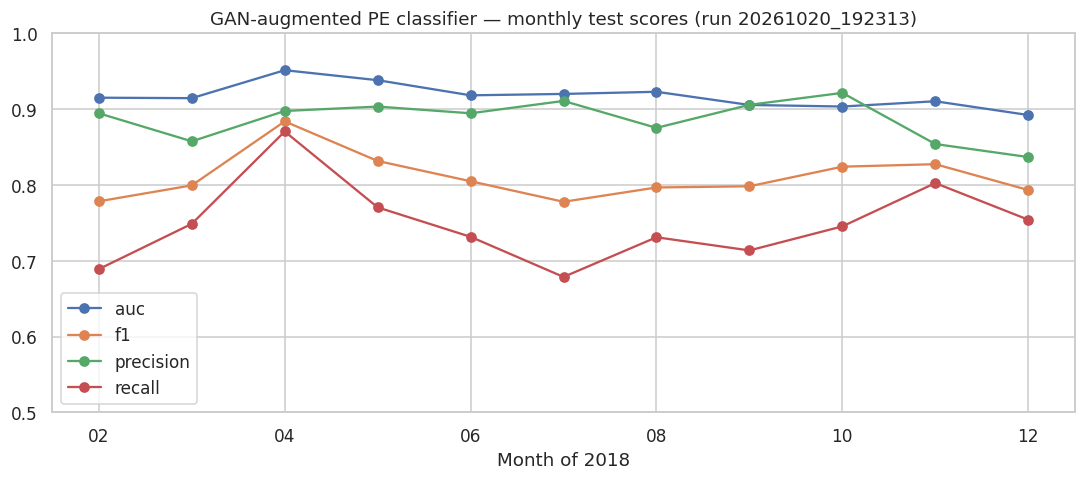

month,02,03,04,05,06,07,08,09,10,11,12
auc,0.915,0.915,0.952,0.938,0.918,0.920,0.923,0.906,0.904,0.911,0.892
accuracy,0.774,0.818,0.882,0.849,0.816,0.799,0.821,0.787,0.792,0.833,0.804
f1,0.779,0.800,0.884,0.832,0.805,0.778,0.797,0.798,0.824,0.828,0.793
precision,0.895,0.858,0.898,0.904,0.895,0.911,0.875,0.906,0.922,0.854,0.837
recall,0.689,0.749,0.871,0.771,0.732,0.679,0.731,0.714,0.745,0.803,0.754


In [5]:
run = latest_run(EXP / "pe_gan_training", "concept_drift.csv")
if run is not None:
    gan_drift = pd.read_csv(run / "concept_drift.csv", dtype={"month": str})
    gan_drift = gan_drift[gan_drift.month != "mean"]
    ax = gan_drift.set_index("month")[["auc", "f1", "precision", "recall"]].plot(marker="o", figsize=(10, 4.5))
    ax.set_ylim(0.5, 1.0); ax.set_title(f"GAN-augmented PE classifier — monthly test scores (run {run.name})")
    ax.set_xlabel("Month of 2018"); plt.tight_layout(); plt.show()
    display(gan_drift.set_index("month").T.round(3))
else:
    missing(EXP / "pe_gan_training/<run>/concept_drift.csv", "train_pe_gan")

Precision stays high (~0.85–0.92) while **recall** is what moves month to month: drift on EMBER is mainly *new malware
the model has not seen* (missed detections), not benign files being flagged. This is consistent with malware families
evolving faster than benign software.

## 3. Concept drift — NIDS domain (chronological chunks)

In [6]:
nids_drift_path = DRIFT / "NIDS_concept_drift_metrics.csv"
if nids_drift_path.exists():
    nids_drift = pd.read_csv(nids_drift_path)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, metric in zip(axes, ["F1", "Recall"]):
        for model, g in nids_drift.groupby("Model"):
            ax.plot(g.Chunk, g[metric], marker="o", lw=3 if model == GNN_NAME else 1.3, label=model)
        ax.set_title(f"NIDS — {metric} per held-out chunk"); ax.set_xlabel("Chunk (later →)"); ax.set_ylim(0, 1.05)
    axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.show()
    display(nids_drift.pivot(index="Model", columns="Chunk", values="F1").round(3))
else:
    missing(nids_drift_path, "eval_drift")

[Missing] /home/simone/UNI/Master/Tesi/thesis-project/experiments/concept_drift/NIDS_concept_drift_metrics.csv
Run first:  python orchestrator.py -t eval_drift


**Takeaways to write in the thesis**
* State the clean ranking (section 1) and whether the GNN advantage, if any, is larger than the run-to-run spread from notebook 03.
* For drift, the useful number is the **slope / drop from first to last period** and its **variance**, not only the mean.
  A model with lower mean but flatter curve needs retraining less often.
* NIDS chunks are short (few malicious windows per chunk), so single-chunk F1 values are noisy; comment on trends, not individual points.